<center><h1>Xu_Yilong_HW5</h1></center>
<br>
<br>

Name: Yilong Xu
<br>
Github Username: yilongxu-usc
<br>
USC ID: 9633003204

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:

columns = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pain",
    "Urethra_Burning",
    "Bladder_Inflammation",
    "Renal_Pelvis_Nephritis"
]

df = pd.read_csv(
    "../data/diagnosis.data",
    sep="\t",
    header=None,
    names=columns,
    encoding="utf-16"
)

# Convert temperature to numeric values
df["Temperature"] = (
    df["Temperature"].str.replace(",", ".", regex=False).astype(float)
)

# Convert yes/no values to 1/0
for col in df.columns[1:]:
    df[col] = df[col].map({"yes": 1, "no": 0})

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

df.head()


X = df.iloc[:, :6]
y = df.iloc[:, 6:]

print("Features shape:", X.shape)
print("Labels shape:", y.shape)



Dataset shape: (120, 8)
Missing values: 0
Features shape: (120, 6)
Labels shape: (120, 2)


### (b) Build a decision tree

Training Accuracy: 1.0
Tree Depth: 4
Number of Leaves: 6


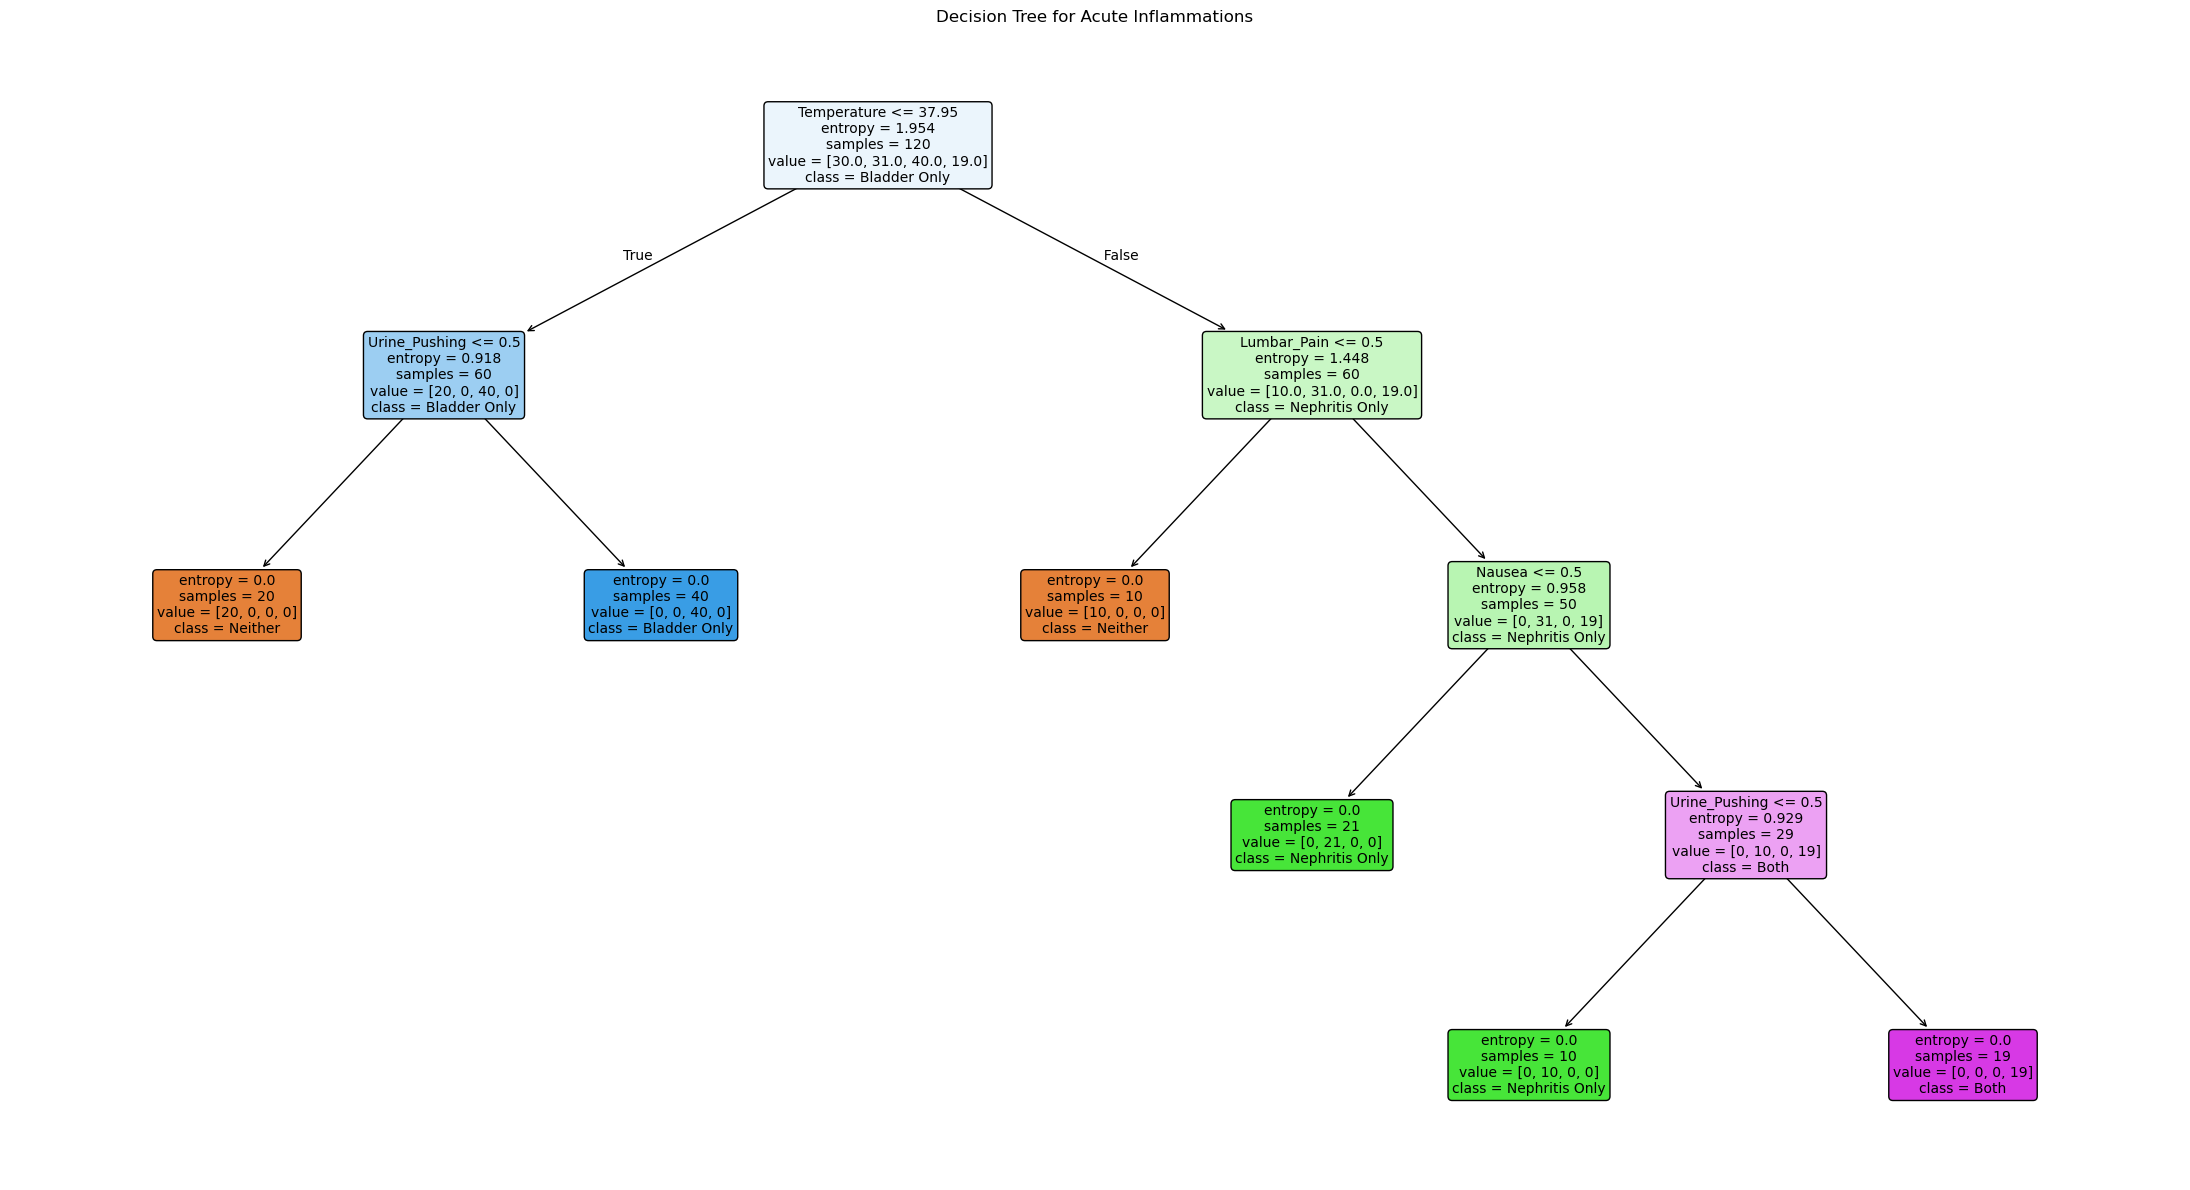

In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Combine the two diagnosis labels into one multiclass target
y_combined = (
    y["Bladder_Inflammation"].astype(str)
    + y["Renal_Pelvis_Nephritis"].astype(str)
)

# Build and train the decision tree on the entire dataset
dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

dt.fit(X, y_combined)

print("Training Accuracy:", dt.score(X, y_combined))
print("Tree Depth:", dt.get_depth())
print("Number of Leaves:", dt.get_n_leaves())

class_names = [
    "Neither",
    "Nephritis Only",
    "Bladder Only",
    "Both"
]

plt.figure(figsize=(22, 12))

plot_tree(
    dt,
    feature_names=X.columns,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

A decision tree classifier was trained on the entire dataset using entropy as the splitting criterion. The two diagnosis labels were combined into four classes using the Label Powerset method. The resulting decision tree achieved 100% training accuracy, with a maximum depth of 4 and 6 leaf nodes. The tree uses temperature, urine pushing, lumbar pain, and nausea to classify the four diagnosis combinations.

### (c) Convert the decision rules

In [4]:
from sklearn.tree import _tree

def tree_to_rules(model, feature_names):
    tree_ = model.tree_
    rules = []

    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]

            recurse(
                tree_.children_left[node],
                conditions + [f"{feature} <= {threshold:.2f}"]
            )
            recurse(
                tree_.children_right[node],
                conditions + [f"{feature} > {threshold:.2f}"]
            )
        else:
            class_index = np.argmax(tree_.value[node][0])
            predicted_class = model.classes_[class_index]
            rules.append((conditions, predicted_class))

    recurse(0, [])

    for i, (conditions, prediction) in enumerate(rules, 1):
        print(f"Rule {i}:")
        print("IF " + " AND ".join(conditions))
        print(f"THEN Class = {prediction}\n")

tree_to_rules(dt, list(X.columns))


Rule 1:
IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN Class = 00

Rule 2:
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN Class = 10

Rule 3:
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN Class = 00

Rule 4:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50
THEN Class = 01

Rule 5:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50
THEN Class = 01

Rule 6:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50
THEN Class = 11



### (d) Cost-complexity pruning

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Obtain cost-complexity pruning parameters
path = dt.cost_complexity_pruning_path(X, y_combined)
ccp_alphas = path.ccp_alphas

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        criterion="entropy",
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(X, y_combined)

    scores = cross_val_score(
        model, X, y_combined,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "ccp_alpha": alpha,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Training Accuracy": model.score(X, y_combined),
        "CV Accuracy": scores.mean()
    })

pruning_results = pd.DataFrame(results)
print(pruning_results.round(4))

   ccp_alpha  Depth  Leaves  Training Accuracy  CV Accuracy
0     0.0000      4       6             1.0000       1.0000
1     0.1996      2       4             0.8417       0.8667
2     0.3250      2       3             0.7583       0.7667
3     0.4591      1       2             0.5917       0.6333
4     0.7704      0       1             0.3333       0.4833


Best alpha: 0.1996
Training Accuracy: 0.8417
Tree Depth: 2
Number of Leaves: 4


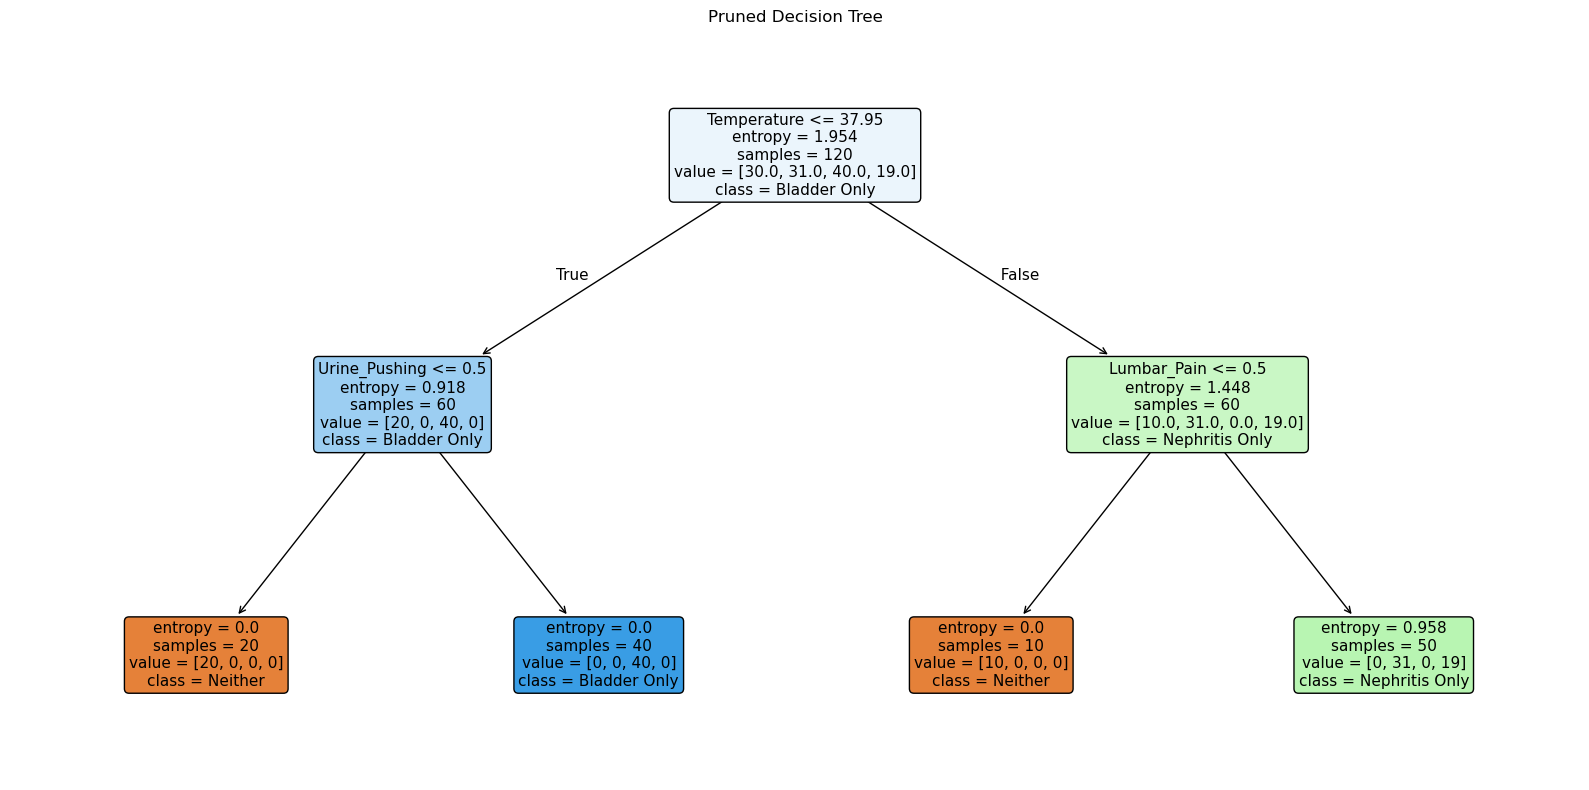

IF-THEN Rules for the Pruned Decision Tree:

Rule 1:
IF Temperature <= 37.95 AND Urine_Pushing <= 0.50
THEN Class = 00

Rule 2:
IF Temperature <= 37.95 AND Urine_Pushing > 0.50
THEN Class = 10

Rule 3:
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50
THEN Class = 00

Rule 4:
IF Temperature > 37.95 AND Lumbar_Pain > 0.50
THEN Class = 01



In [6]:
# Select the best strictly pruned tree by CV accuracy
pruned_results = pruning_results[
    (pruning_results["ccp_alpha"] > 0) &
    (pruning_results["Leaves"] > 1)
]

best_row = pruned_results.sort_values(
    ["CV Accuracy", "Leaves"],
    ascending=[False, True]
).iloc[0]

best_alpha = best_row["ccp_alpha"]

# Train the pruned decision tree
pruned_dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_dt.fit(X, y_combined)

print("Best alpha:", round(best_alpha, 4))
print("Training Accuracy:", round(pruned_dt.score(X, y_combined), 4))
print("Tree Depth:", pruned_dt.get_depth())
print("Number of Leaves:", pruned_dt.get_n_leaves())

# Plot the pruned tree
plt.figure(figsize=(16, 8))

plot_tree(
    pruned_dt,
    feature_names=X.columns,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=11
)

plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.show()

print("IF-THEN Rules for the Pruned Decision Tree:\n")

tree_to_rules(pruned_dt, list(X.columns))


Cost-complexity pruning was applied to simplify the original decision tree. Different values of ccp_alpha were evaluated using 5-fold stratified cross-validation. The original tree had 6 leaf nodes, a maximum depth of 4, and 100% training and cross-validation accuracy. Among the strictly pruned trees, the best model used ccp_alpha = 0.1996, reducing the tree to 4 leaf nodes and a maximum depth of 2, with 84.17% training accuracy and 86.67% cross-validation accuracy.

The pruned tree produced four IF-THEN rules using only temperature, urine pushing, and lumbar pain. Although the rules are easier to interpret, the simplified tree can no longer identify patients with both diagnoses. Therefore, pruning improves interpretability at the cost of predictive performance.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [7]:
import re

# Extract column names from the dataset description
with open("../data/communities.names", "r", encoding="latin-1") as f:
    column_names = re.findall(
        r"^@attribute\s+(\S+)",
        f.read(),
        flags=re.MULTILINE
    )

# Load the dataset
crime_df = pd.read_csv(
    "../data/communities.data",
    header=None,
    names=column_names,
    na_values="?"
)

print("Dataset shape:", crime_df.shape)

# Split the dataset according to the assignment
train_df = crime_df.iloc[:1495].copy()
test_df = crime_df.iloc[1495:].copy()

print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)


Dataset shape: (1994, 128)
Training set shape: (1495, 128)
Test set shape: (499, 128)


### (b) Missing values

In [8]:
from sklearn.impute import SimpleImputer

# Remove non-predictive features
non_predictive = [
    "state", "county", "community", "communityname", "fold"
]

target = "ViolentCrimesPerPop"

X_train = train_df.drop(columns=non_predictive + [target])
X_test = test_df.drop(columns=non_predictive + [target])

y_train = train_df[target]
y_test = test_df[target]

# Check missing values before imputation
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())
print("Features with missing values:", (X_train.isnull().sum() > 0).sum())

Training missing values: 27633
Testing missing values: 9218
Features with missing values: 23


In [9]:
# Apply median imputation
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verify the results
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training set shape: (1495, 122)
Testing set shape: (499, 122)
Training missing values: 0
Testing missing values: 0


The five non-predictive features (state, county, community, communityname, and fold) were removed from the dataset. The target variable, ViolentCrimesPerPop, was separated from the predictive features. Missing values were handled using median imputation, which is less sensitive to outliers than mean imputation. The imputer was fitted on the training data and then applied to both the training and test sets to avoid data leakage. After imputation, both datasets contained 122 predictive features with no remaining missing values.

### (c) Plot a correlation matrix

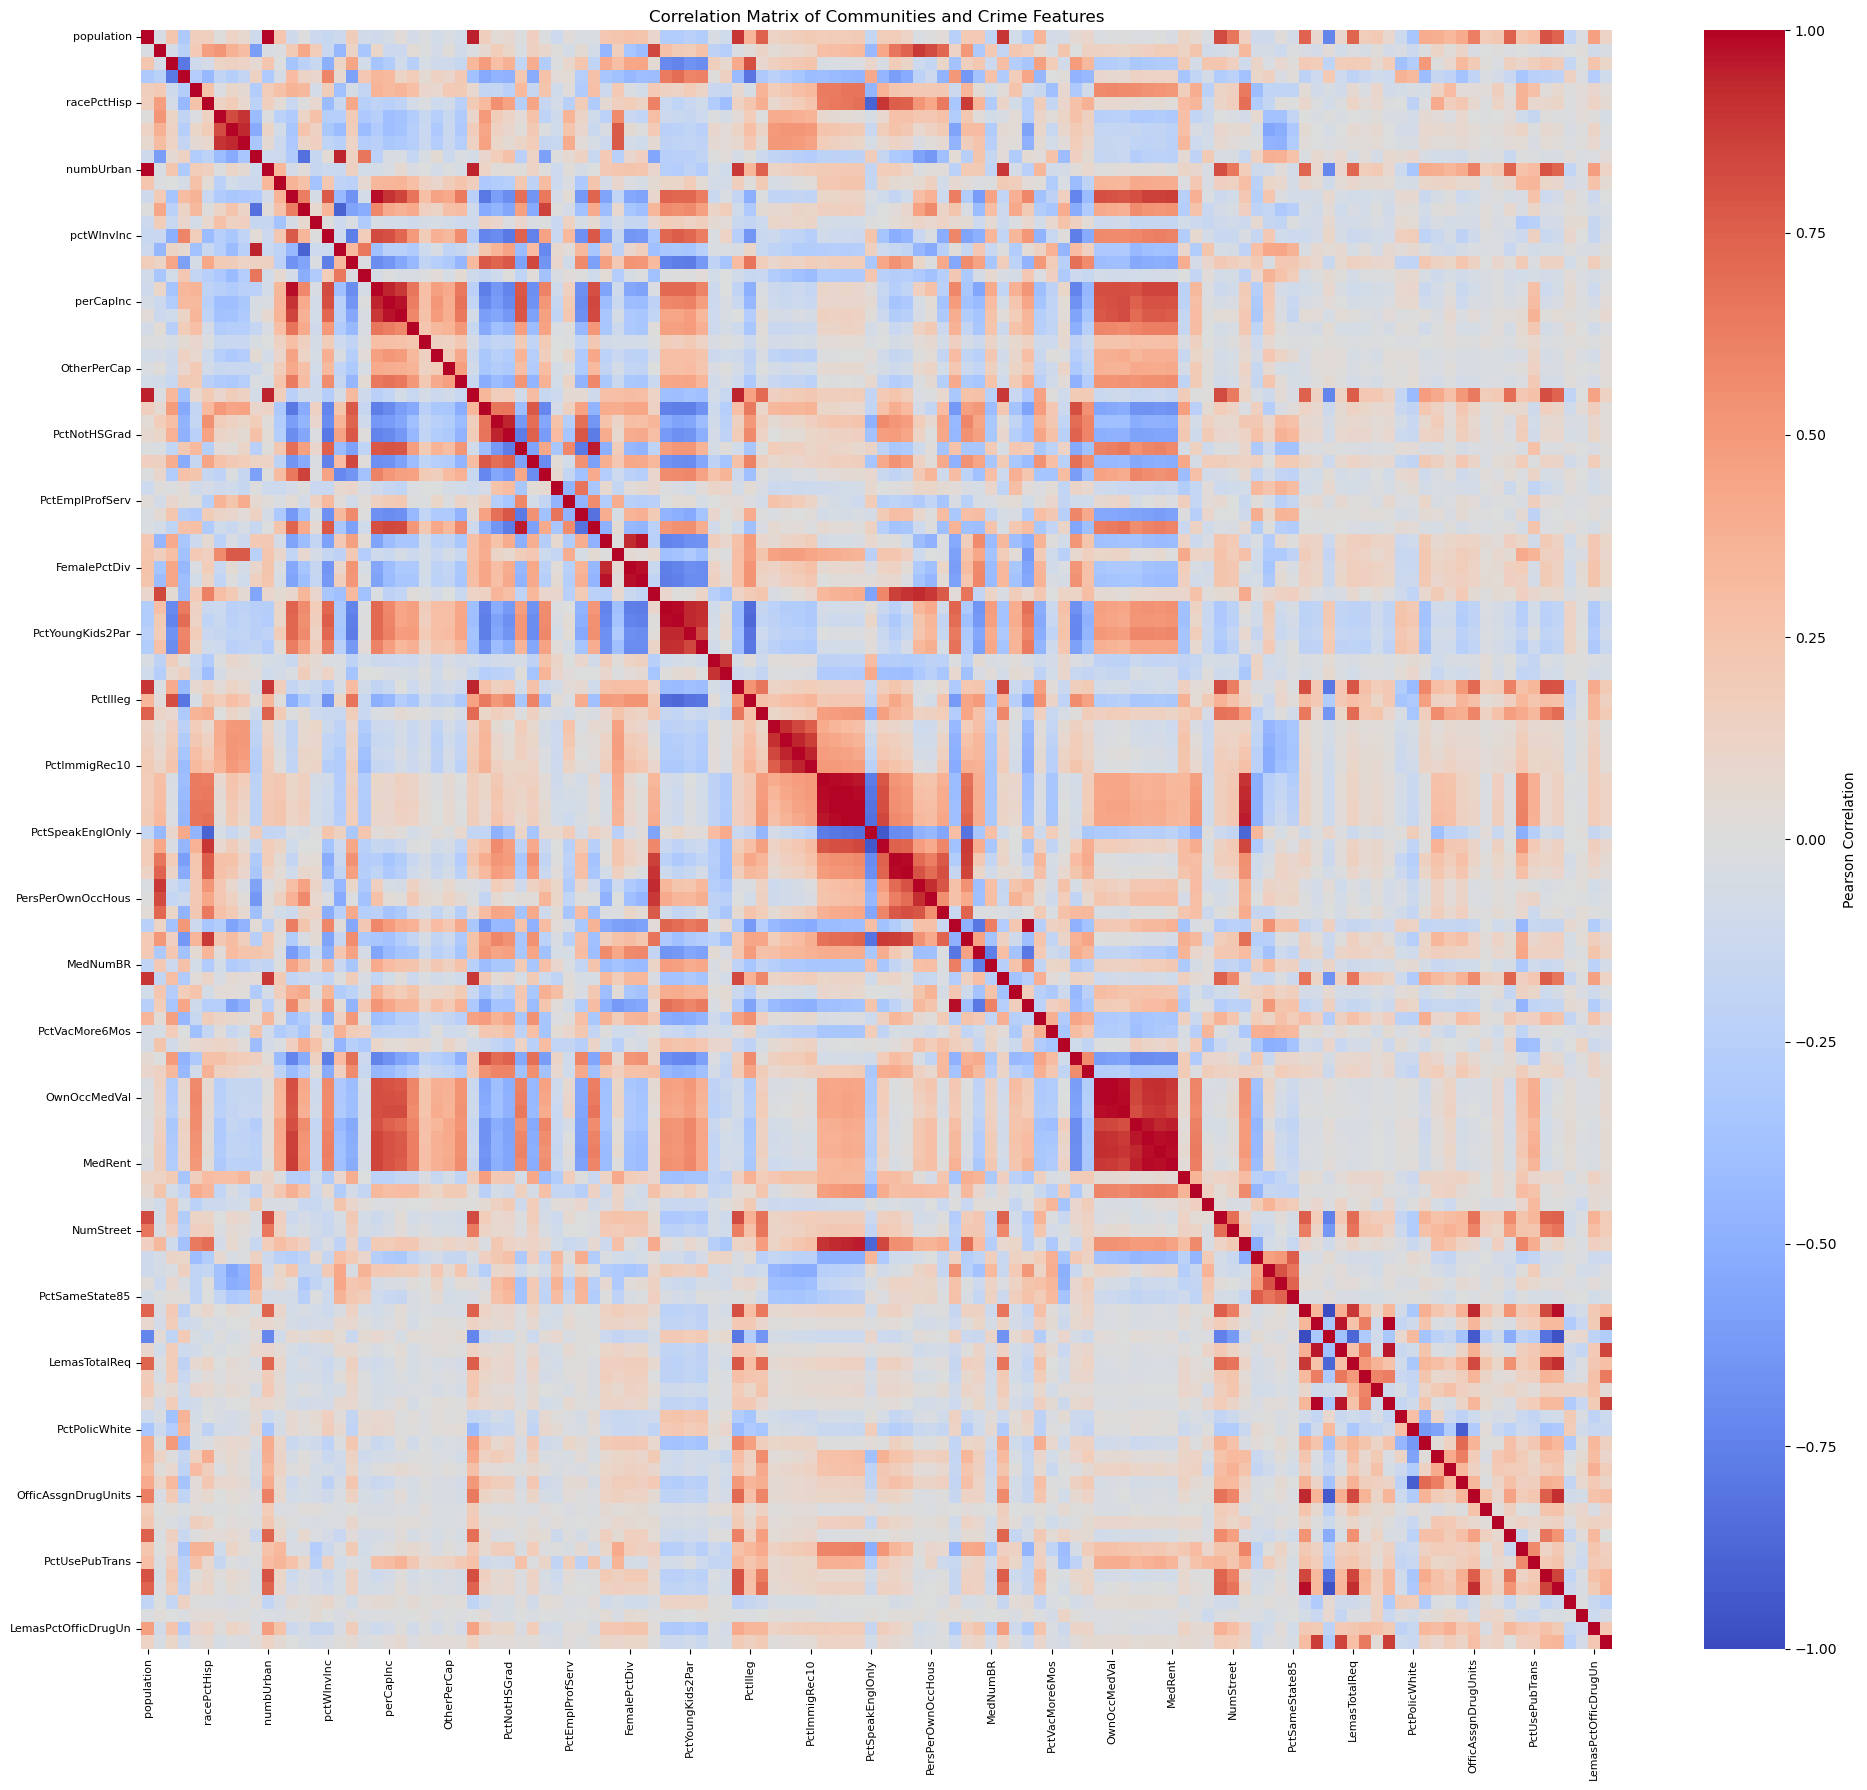

In [10]:
import seaborn as sns

# Calculate Pearson correlation matrix
corr_matrix = X_train.corr()

# Plot correlation heatmap
plt.figure(figsize=(20, 18))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    xticklabels=5,
    yticklabels=5,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Matrix of Communities and Crime Features")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [11]:
# Calculate the coefficient of variation for each feature
cv = X_train.std(ddof=1) / X_train.mean()

# Sort features by CV in descending order
cv_df = pd.DataFrame({
    "Feature": cv.index,
    "CV": cv.values
}).sort_values(by="CV", ascending=False)

cv_df = cv_df.reset_index(drop=True)

print("Number of features:", len(cv_df))
display(cv_df)

Number of features: 122


,Feature,CV
0,PctPolicAsian,5.527059
1,NumStreet,4.292923
2,NumInShelters,3.470952
3,NumIlleg,3.058964
4,NumImmig,2.926635
...,...,...
117,NumKindsDrugsSeiz,0.141021
118,RacialMatchCommPol,0.129652
119,PctPolicWhite,0.118727
120,LemasPctPolicOnPatr,0.112032


### (e) Scatter plots and box plots for highest CV features

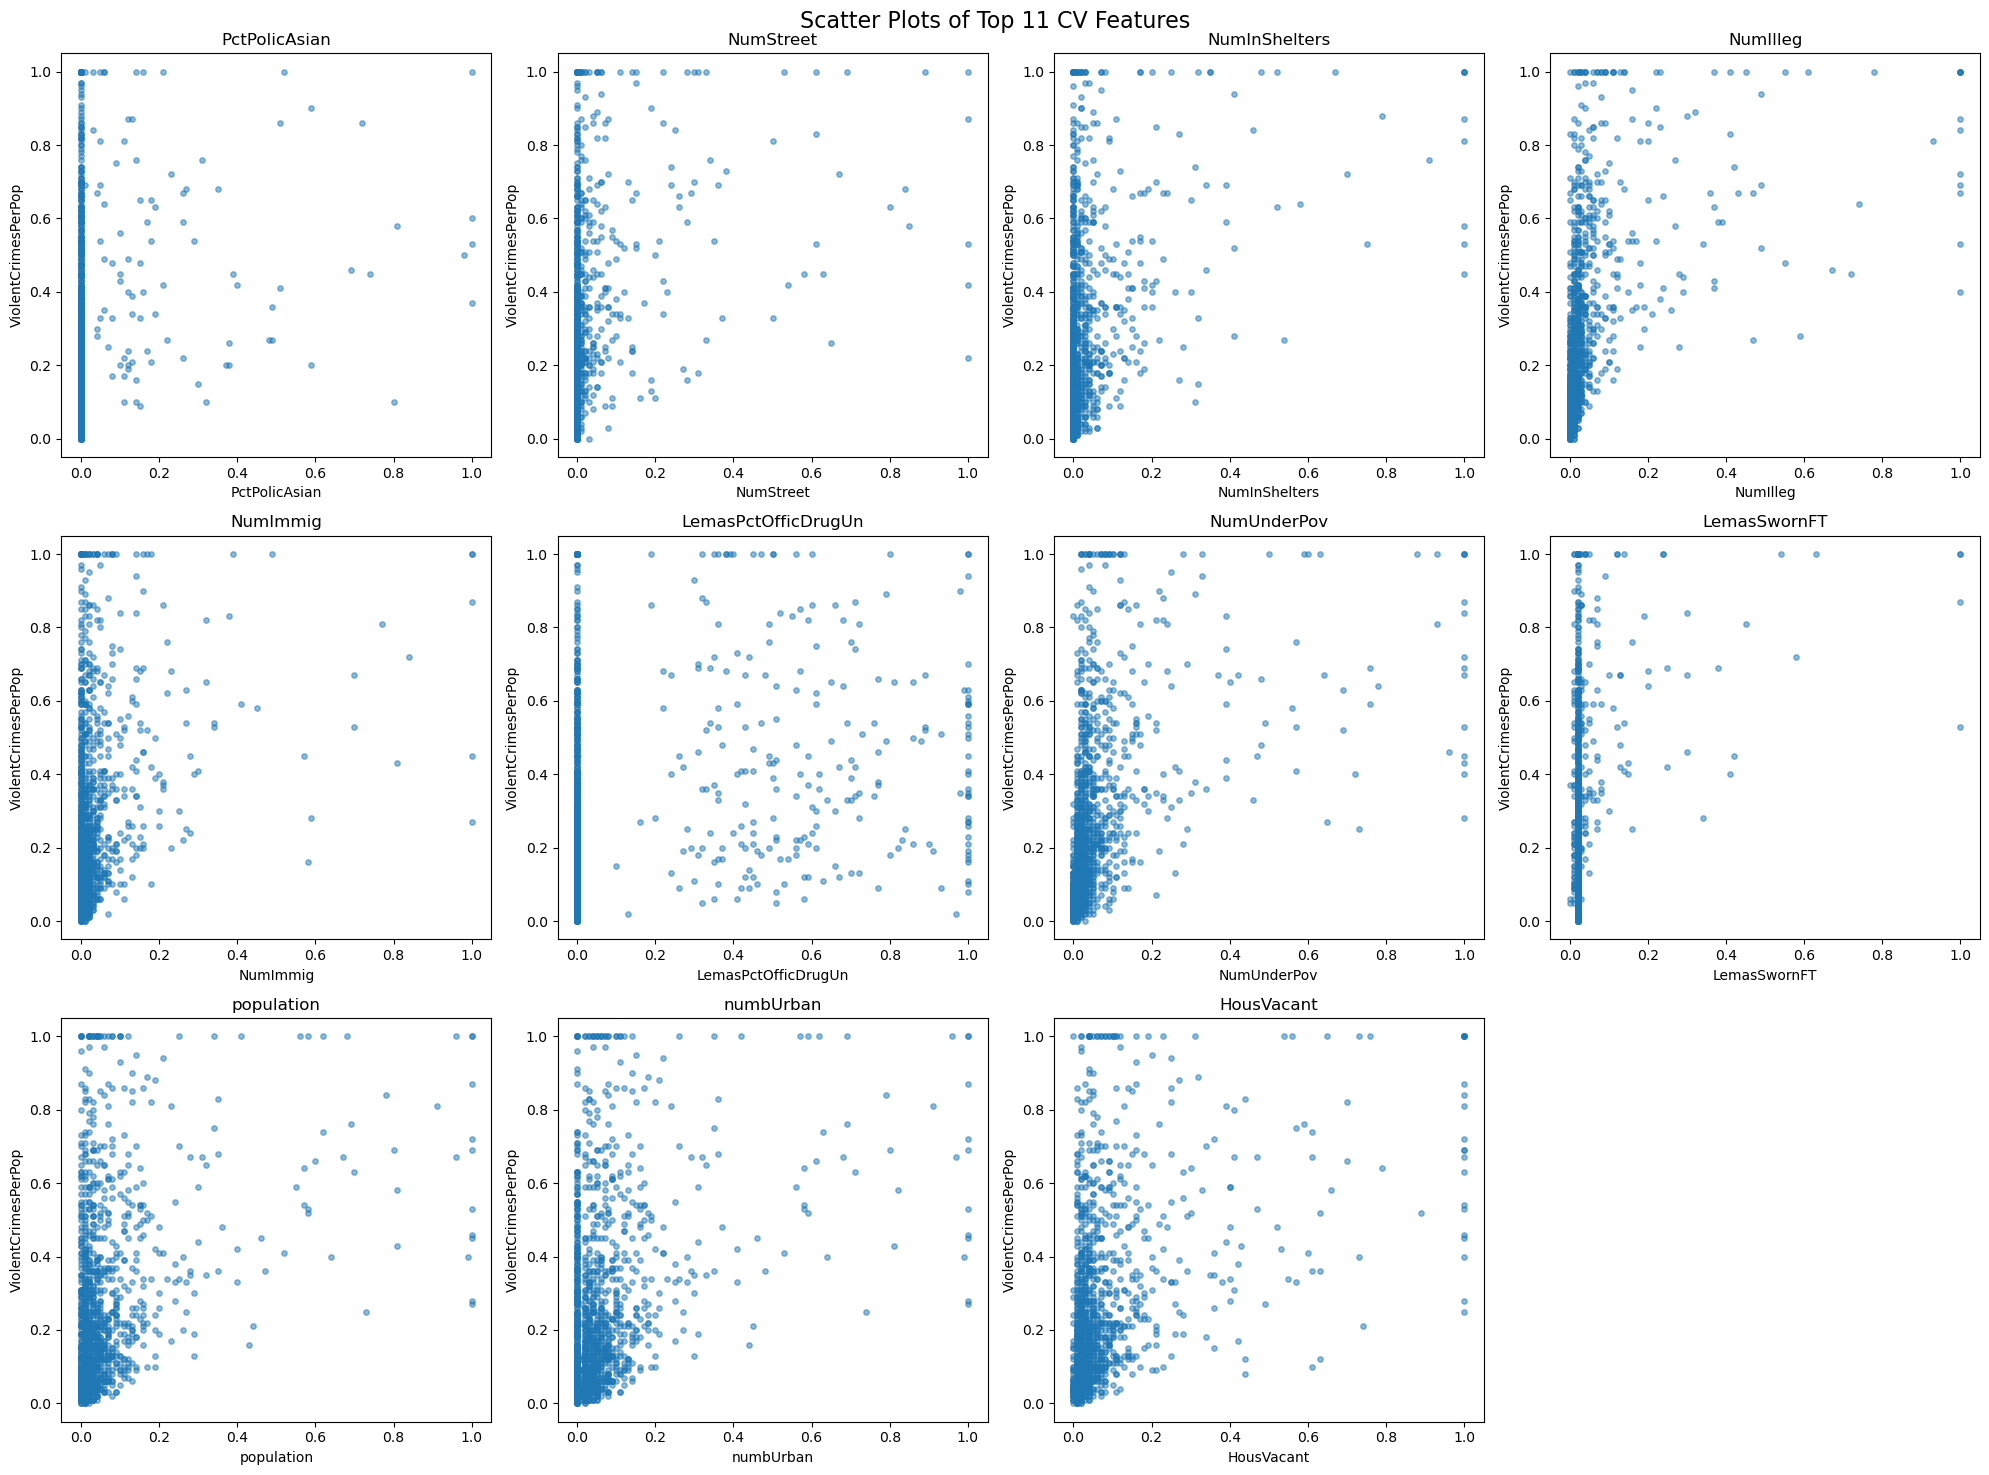

In [12]:
# Select the 11 features with the highest CV
n_features = int(np.sqrt(128))

top_features = cv_df.head(n_features)["Feature"].tolist()

fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(
        X_train[feature],
        y_train,
        alpha=0.5,
        s=15
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("ViolentCrimesPerPop")

for i in range(len(top_features), len(axes)):
    axes[i].axis("off")

plt.suptitle("Scatter Plots of Top 11 CV Features", fontsize=16)
plt.tight_layout()
plt.show()



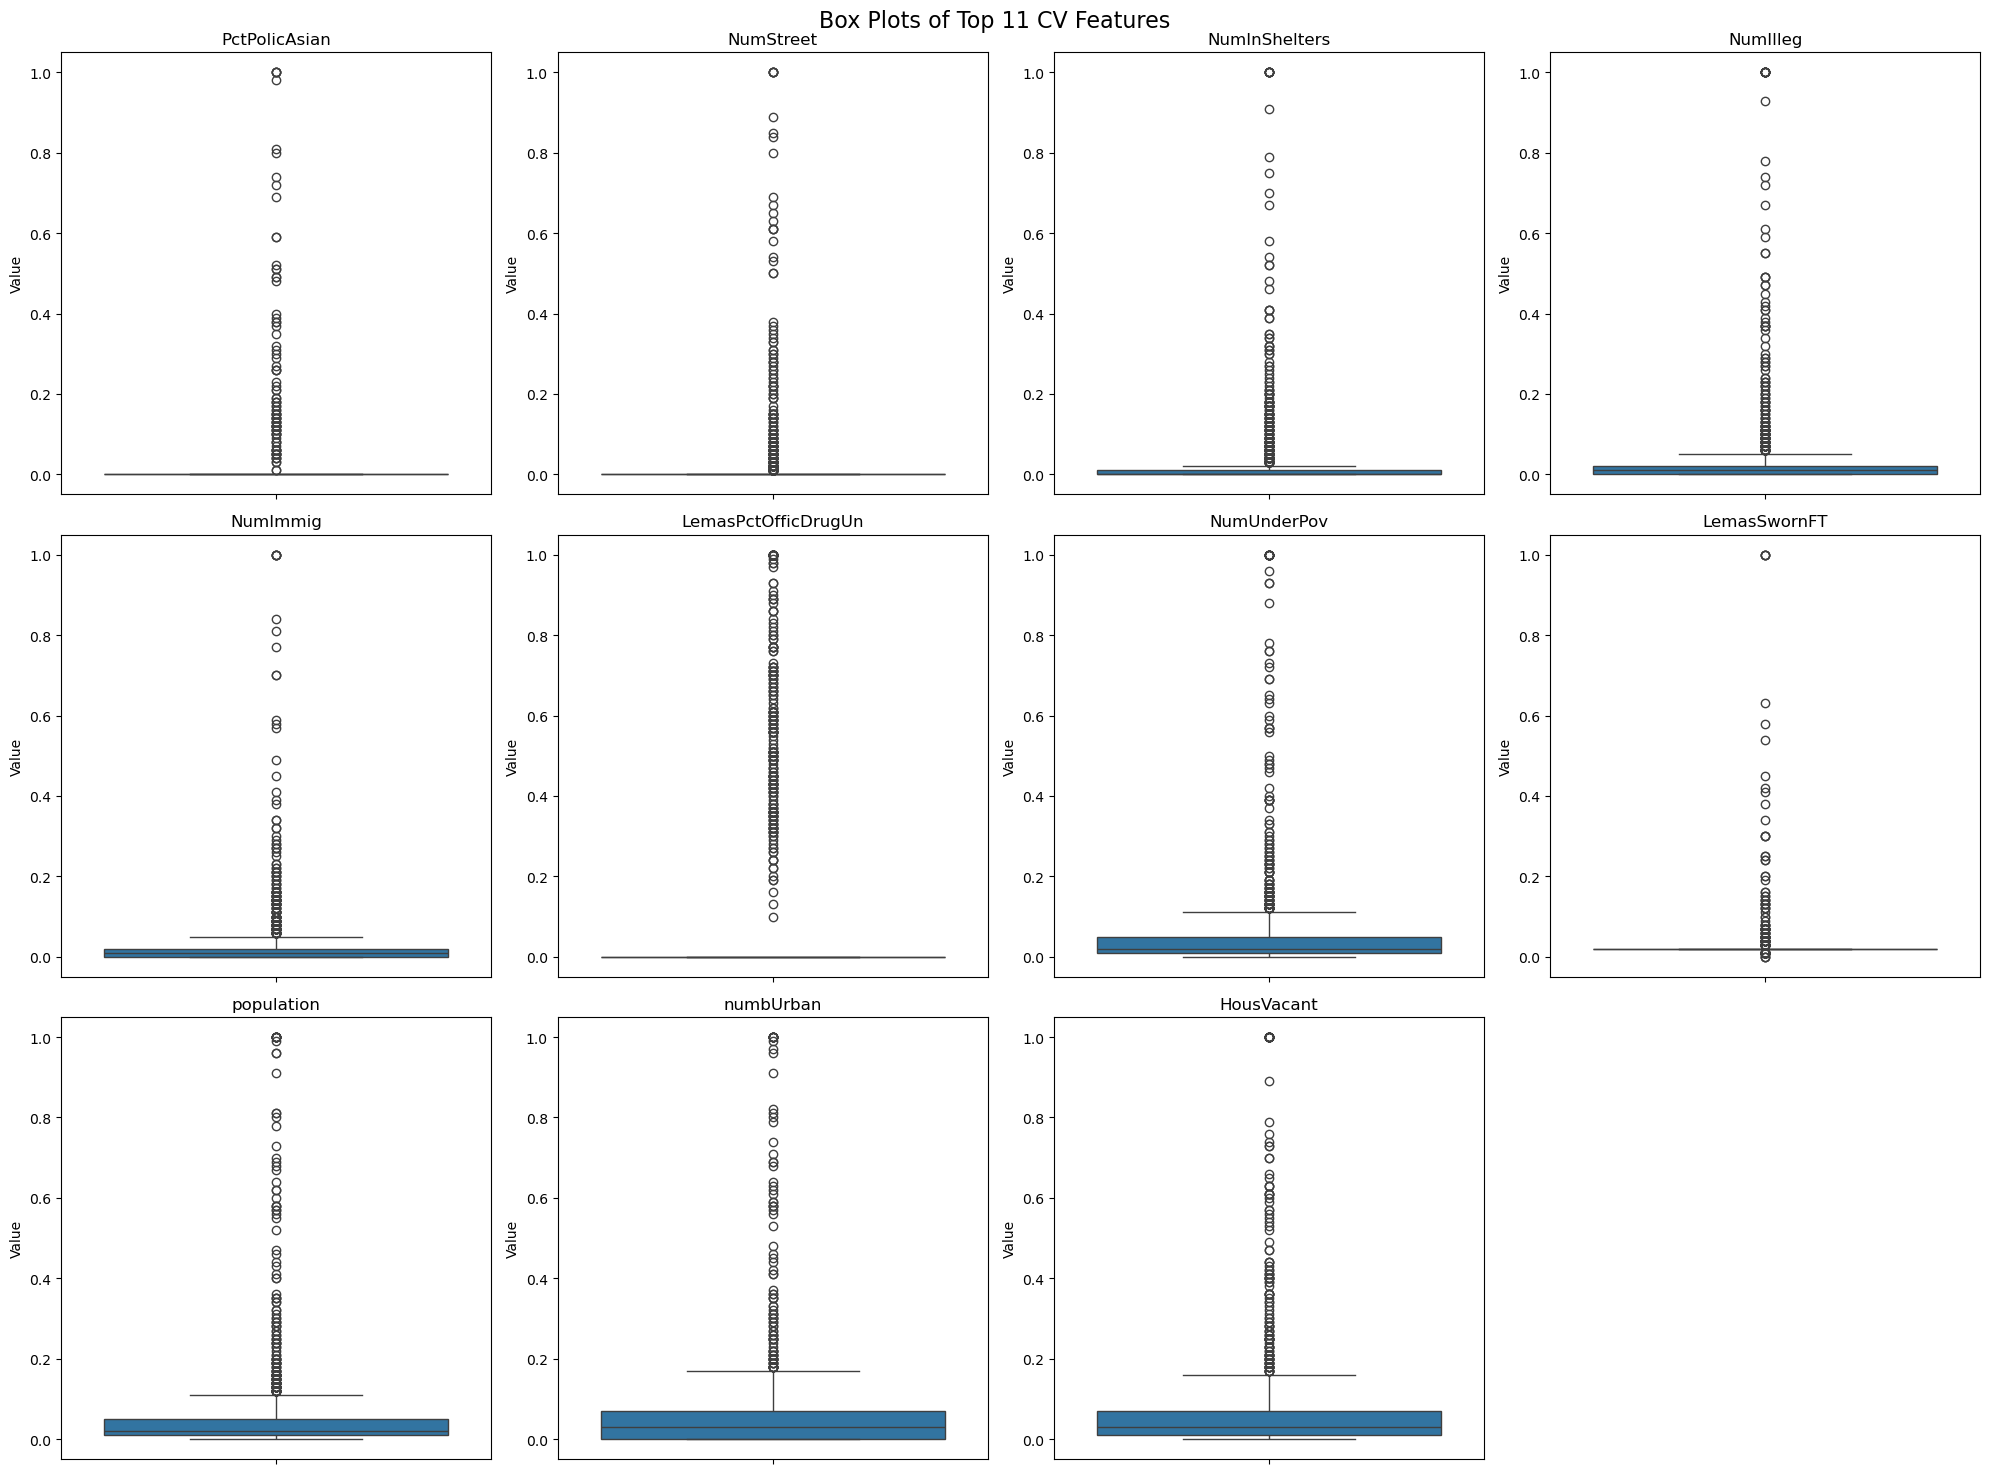

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        y=X_train[feature],
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_ylabel("Value")

for i in range(len(top_features), len(axes)):
    axes[i].axis("off")

plt.suptitle("Box Plots of Top 11 CV Features", fontsize=16)
plt.tight_layout()
plt.show()


The 11 features with the highest coefficients of variation were selected for visualization. Scatter plots were created to examine their relationships with ViolentCrimesPerPop, and box plots were used to examine their distributions and potential outliers.

Some features, such as NumIlleg, NumUnderPov, and HousVacant, show positive associations with violent crime rates. The box plots also suggest that several features have skewed distributions and outliers.

However, scatter plots alone cannot determine whether these features are statistically significant. They only provide a visual understanding of possible relationships. Further statistical analysis and regression modeling are needed to evaluate their predictive importance.

### (f) Fit a linear model

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Fit linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict on the test set
y_pred_linear = linear_model.predict(X_test)

# Calculate test error
linear_test_mse = mean_squared_error(y_test, y_pred_linear)

print("Linear Regression Test MSE:", linear_test_mse)


Linear Regression Test MSE: 0.01796621542606734


The resulting test Mean Squared Error (MSE) was approximately 0.01797

### (g) Fit a ridge regression model

In [15]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

# Define candidate lambda values
alphas = np.logspace(-4, 4, 100)

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Fit Ridge Regression with cross-validation
ridge_model = RidgeCV(
    alphas=alphas,
    cv=cv,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train, y_train)

# Predict on the test set
y_pred_ridge = ridge_model.predict(X_test)

# Calculate test error
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

print("Optimal Lambda:", ridge_model.alpha_)
print("Ridge Regression Test MSE:", ridge_test_mse)


Optimal Lambda: 3.351602650938848
Ridge Regression Test MSE: 0.017472388425329194


The optimal λ was approximately 3.3516, and the resulting test Mean Squared Error (MSE) was 0.01747.

### (h) Fit a LASSO model

In [16]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Define candidate lambda values
alphas = np.logspace(-4, -1, 60)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Fit LASSO using cross-validation
lasso_search = GridSearchCV(
    Lasso(max_iter=30000, random_state=42),
    param_grid={"alpha": alphas},
    cv=cv,
    scoring="neg_mean_squared_error"
)

lasso_search.fit(X_train, y_train)

lasso_model = lasso_search.best_estimator_

# Calculate test MSE
y_pred_lasso = lasso_model.predict(X_test)
lasso_test_mse = mean_squared_error(y_test, y_pred_lasso)

# Get selected features with nonzero coefficients
lasso_selected = pd.Series(
    lasso_model.coef_,
    index=X_train.columns
)

lasso_selected = lasso_selected[lasso_selected.abs() > 1e-8]

print("Optimal Lambda:", lasso_search.best_params_["alpha"])
print("LASSO Test MSE:", lasso_test_mse)
print("Number of Selected Features:", len(lasso_selected))
print("\nSelected Features:")
print(lasso_selected.to_string())


Optimal Lambda: 0.00011242100350620863
LASSO Test MSE: 0.01764195109243147
Number of Selected Features: 73

Selected Features:
racepctblack             0.268238
racePctAsian            -0.015761
agePct12t21              0.068128
agePct12t29             -0.270848
pctUrban                 0.040891
pctWWage                -0.085725
pctWFarmSelf             0.027133
pctWInvInc              -0.102273
pctWSocSec               0.052185
pctWPubAsst              0.040761
pctWRetire              -0.108705
whitePerCap             -0.054753
blackPerCap             -0.021921
indianPerCap            -0.030723
AsianPerCap              0.028706
OtherPerCap              0.023076
HispPerCap               0.023504
PctPopUnderPov          -0.141638
PctLess9thGrade         -0.020172
PctEmploy                0.141977
PctEmplManu             -0.015823
PctOccupManu             0.011516
MalePctDivorce           0.120002
MalePctNevMarr           0.137255
FemalePctDiv            -0.084654
PctKids2Par            

In [17]:
# Create pipeline with standardization and LASSO
lasso_std_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=30000, random_state=42))
])

# Select optimal lambda using cross-validation
lasso_std_search = GridSearchCV(
    lasso_std_pipeline,
    param_grid={"lasso__alpha": alphas},
    cv=cv,
    scoring="neg_mean_squared_error"
)

lasso_std_search.fit(X_train, y_train)

lasso_std_model = lasso_std_search.best_estimator_

# Calculate test MSE
y_pred_lasso_std = lasso_std_model.predict(X_test)
lasso_std_test_mse = mean_squared_error(
    y_test, y_pred_lasso_std
)

# Get selected features
lasso_std_selected = pd.Series(
    lasso_std_model.named_steps["lasso"].coef_,
    index=X_train.columns
)

lasso_std_selected = lasso_std_selected[
    lasso_std_selected.abs() > 1e-8
]

print("Optimal Lambda:",
      lasso_std_search.best_params_["lasso__alpha"])
print("Standardized LASSO Test MSE:", lasso_std_test_mse)
print("Number of Selected Features:", len(lasso_std_selected))
print("\nSelected Features:")
print(lasso_std_selected.to_string())


Optimal Lambda: 0.0006509675230458171
Standardized LASSO Test MSE: 0.01771658125015481
Number of Selected Features: 76

Selected Features:
racepctblack             0.067966
racePctAsian            -0.001740
agePct12t21              0.012098
agePct12t29             -0.042477
pctUrban                 0.017052
pctWWage                -0.014020
pctWFarmSelf             0.004730
pctWInvInc              -0.022024
pctWSocSec               0.010205
pctWPubAsst              0.007694
pctWRetire              -0.017715
whitePerCap             -0.009545
blackPerCap             -0.003895
indianPerCap            -0.005248
AsianPerCap              0.005408
OtherPerCap              0.004036
HispPerCap               0.004273
PctPopUnderPov          -0.028970
PctLess9thGrade         -0.003279
PctEmploy                0.024613
PctEmplManu             -0.001603
PctOccupManu             0.000633
MalePctDivorce           0.020971
MalePctNevMarr           0.024085
FemalePctDiv            -0.014065
PctKids2Par

In [18]:
# Compare LASSO models
comparison = pd.DataFrame({
    "Model": [
        "LASSO",
        "Standardized LASSO"
    ],
    "Optimal Lambda": [
        lasso_search.best_params_["alpha"],
        lasso_std_search.best_params_["lasso__alpha"]
    ],
    "Test MSE": [
        lasso_test_mse,
        lasso_std_test_mse
    ],
    "Selected Features": [
        len(lasso_selected),
        len(lasso_std_selected)
    ]
})

print(comparison.to_string(index=False))


             Model  Optimal Lambda  Test MSE  Selected Features
             LASSO        0.000112  0.017642                 73
Standardized LASSO        0.000651  0.017717                 76


The original LASSO model achieved a slightly lower test error than the standardized model. Since the dataset's features were already normalized, additional standardization did not improve predictive performance in this experiment. Both models reduced the number of predictors by shrinking some coefficients to zero.

### (i) Fit a PCR model

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Define PCR pipeline
pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])

# Try all possible numbers of principal components
n_components = np.arange(1, X_train.shape[1] + 1)

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pcr_search = GridSearchCV(
    pcr_pipeline,
    param_grid={"pca__n_components": n_components},
    cv=cv,
    scoring="neg_mean_squared_error"
)

pcr_search.fit(X_train, y_train)

# Best model and optimal number of components
pcr_model = pcr_search.best_estimator_
best_m = pcr_search.best_params_["pca__n_components"]

# Predict on the test set
y_pred_pcr = pcr_model.predict(X_test)

# Calculate test MSE
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)

print("Optimal Number of Components:", best_m)
print("Cross-Validation MSE:", -pcr_search.best_score_)
print("PCR Test MSE:", pcr_test_mse)


Optimal Number of Components: 60
Cross-Validation MSE: 0.020206611106055504
PCR Test MSE: 0.018349525286169944


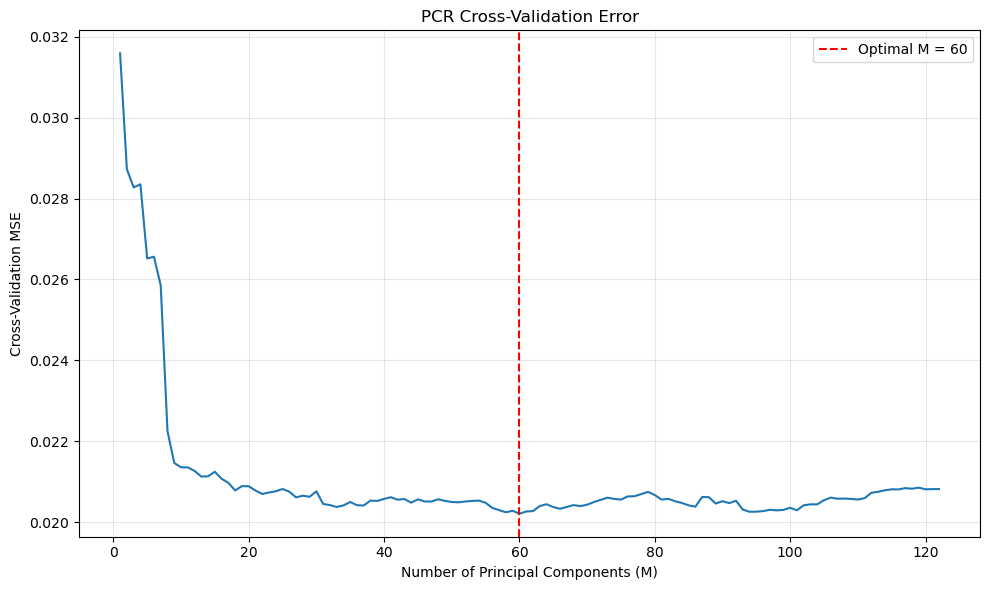

In [20]:
# Extract cross-validation errors
cv_mse = -pcr_search.cv_results_["mean_test_score"]

# Plot CV MSE for different numbers of components
plt.figure(figsize=(10, 6))

plt.plot(n_components, cv_mse)

plt.axvline(
    x=best_m,
    color="red",
    linestyle="--",
    label=f"Optimal M = {best_m}"
)

plt.xlabel("Number of Principal Components (M)")
plt.ylabel("Cross-Validation MSE")
plt.title("PCR Cross-Validation Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


The optimal number of principal components was M = 60, with a cross-validation MSE of approximately 0.02021. The resulting test MSE was 0.01835.

### (j) Fit a boosting tree

In [21]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error

# Define XGBoost regression model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

# Candidate alpha values
alphas = [0, 0.0001, 0.001, 0.01, 0.1,
          0.3, 1, 3, 10, 30]

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

xgb_search = GridSearchCV(
    xgb_model,
    param_grid={"reg_alpha": alphas},
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=2
)

# Fit model
xgb_search.fit(X_train, y_train)

# Best model and optimal alpha
best_xgb = xgb_search.best_estimator_
best_alpha = xgb_search.best_params_["reg_alpha"]

# Predict on test set
y_pred_xgb = best_xgb.predict(X_test)

# Calculate test error
xgb_test_mse = mean_squared_error(y_test, y_pred_xgb)

print("Optimal Alpha:", best_alpha)
print("Cross-Validation MSE:", -xgb_search.best_score_)
print("XGBoost Test MSE:", xgb_test_mse)


Optimal Alpha: 0.1
Cross-Validation MSE: 0.019658669807999372
XGBoost Test MSE: 0.01618128554655902


In [22]:
# Compare all regression models
model_comparison = pd.DataFrame({
    "Model": [
        "OLS",
        "Ridge",
        "LASSO",
        "Standardized LASSO",
        "PCR",
        "XGBoost"
    ],
    "Test MSE": [
        linear_test_mse,
        ridge_test_mse,
        lasso_test_mse,
        lasso_std_test_mse,
        pcr_test_mse,
        xgb_test_mse
    ]
})

model_comparison = model_comparison.sort_values(
    by="Test MSE"
)

print(model_comparison.to_string(index=False))


             Model  Test MSE
           XGBoost  0.016181
             Ridge  0.017472
             LASSO  0.017642
Standardized LASSO  0.017717
               OLS  0.017966
               PCR  0.018350
